In [1]:
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("data/galaxies")
RESULTS = Path("results")

for folder in ["arrays", "tables", "figures"]:
    (RESULTS / folder).mkdir(parents=True, exist_ok=True)

source_path = DATA / "galaxies_processed.csv"
coordinate_path = RESULTS / "arrays/galaxy_coordinates.npz"
table_path = RESULTS / "tables/galaxy_coordinates.csv"

OMEGA_M = 0.332
GRID_SIZE = 10000

settings = {
    "omega_m": OMEGA_M,
    "grid_size": GRID_SIZE,
    "version": 1,
}

digest = hashlib.sha256(source_path.read_bytes())
digest.update(json.dumps(settings, sort_keys=True).encode())
signature = digest.hexdigest()

galaxies = pd.read_csv(source_path, dtype={"specObjID": str})
coordinates = None

if coordinate_path.exists():
    with np.load(coordinate_path, allow_pickle=False) as saved:
        if str(saved["signature"]) == signature:
            coordinates = saved["xyz"]
            distance = saved["distance"]

if coordinates is None:
    z_grid = np.linspace(0, galaxies["z"].max(), GRID_SIZE)
    inverse_E = 1 / np.sqrt(
        OMEGA_M * (1 + z_grid)**3 + 1 - OMEGA_M
    )

    area = (
        (inverse_E[:-1] + inverse_E[1:])
        / 2
        * np.diff(z_grid)
    )
    integral = np.r_[0, np.cumsum(area)]

    distance = (
        2997.92458
        * np.interp(galaxies["z"], z_grid, integral)
    )

    ra = np.deg2rad(galaxies["ra"].to_numpy())
    dec = np.deg2rad(galaxies["dec"].to_numpy())

    coordinates = np.column_stack([
        distance * np.cos(dec) * np.cos(ra),
        distance * np.cos(dec) * np.sin(ra),
        distance * np.sin(dec),
    ])

    if not np.allclose(np.linalg.norm(coordinates, axis=1), distance):
        raise ValueError("거리·좌표 검증 실패")

    temporary = coordinate_path.with_suffix(".tmp")
    with temporary.open("wb") as stream:
        np.savez(
            stream,
            signature=signature,
            xyz=coordinates,
            distance=distance,
            omega_m=OMEGA_M,
        )
    temporary.replace(coordinate_path)

coordinate_table = galaxies.assign(
    distance_hMpc=distance,
    X_hMpc=coordinates[:, 0],
    Y_hMpc=coordinates[:, 1],
    Z_hMpc=coordinates[:, 2],
)
coordinate_table.to_csv(table_path, index=False)

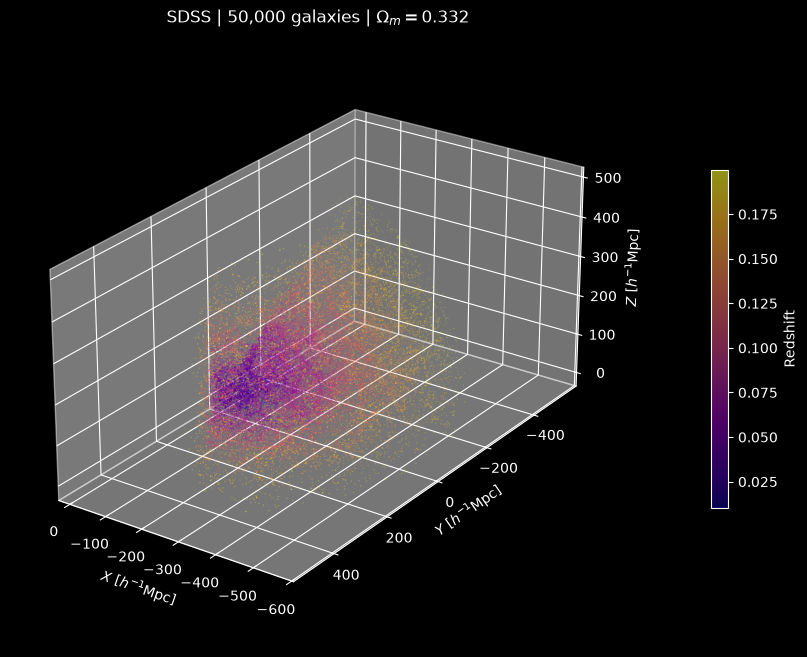

In [2]:
DISPLAY_LIMIT = 50000
SEED = 42

rng = np.random.default_rng(SEED)
indices = rng.choice(
    len(galaxies),
    size=min(DISPLAY_LIMIT, len(galaxies)),
    replace=False,
)

points = coordinates[indices]
redshift = galaxies["z"].to_numpy()[indices]

with plt.style.context("dark_background"):
    fig = plt.figure(figsize=(11, 8))
    ax = fig.add_subplot(111, projection="3d")

    scatter = ax.scatter(
        points[:, 0],
        points[:, 1],
        points[:, 2],
        c=redshift,
        cmap="plasma",
        s=1,
        alpha=0.6,
        linewidths=0,
    )

    ax.set_box_aspect(
        np.maximum(np.ptp(coordinates, axis=0), 1)
    )
    ax.set_xlabel(r"$X\ [h^{-1}\mathrm{Mpc}]$")
    ax.set_ylabel(r"$Y\ [h^{-1}\mathrm{Mpc}]$")
    ax.set_zlabel(r"$Z\ [h^{-1}\mathrm{Mpc}]$")
    ax.set_title(
        f"SDSS | {len(indices):,} galaxies | "
        rf"$\Omega_m={OMEGA_M:.3f}$"
    )
    ax.view_init(elev=25, azim=125)

    fig.colorbar(
        scatter,
        ax=ax,
        label="Redshift",
        shrink=0.55,
        pad=0.1,
    )

    fig.savefig(
        RESULTS / "figures/galaxies_3d.png",
        dpi=200,
        bbox_inches="tight",
    )
    plt.show()